# Vectors, Norms, and Similarity

**AI Mathematics · 1. Linear Algebra**

Represent observations and model parameters as vectors, and learn the operations that appear throughout machine learning.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Create and combine vectors with NumPy.
- Compute dot products, norms, and cosine similarity.
- Recognize shape and zero-vector edge cases.

In [1]:
import numpy as np

## 1. What is a vector?
A vector is an ordered collection of numbers. In machine learning, a feature row, embedding, gradient, or parameter update can be represented as a vector.

In [2]:
import numpy as np

x = np.array([2.0, 1.0, 3.0])
y = np.array([1.0, 4.0, 2.0])
print("x:", x)
print("shape:", x.shape)
print("x + y:", x + y)
print("2x:", 2 * x)
print("x - y:", x - y)

x: [2. 1. 3.]
shape: (3,)
x + y: [3. 5. 5.]
2x: [4. 2. 6.]
x - y: [ 1. -3.  1.]


## 2. Dot product
For vectors of equal length, the dot product is \(x^T y = \sum_i x_i y_i\). It is used in linear models, attention scores, and similarity calculations. NumPy’s `@` operator and `np.dot` both compute it for 1-D arrays.

In [3]:
dot = x @ y
print("dot product:", dot)
print("same with np.dot:", np.dot(x, y))

# A linear model prediction: one weight per feature
weights = np.array([0.5, -1.0, 2.0])
features = np.array([10.0, 3.0, 4.0])
prediction = weights @ features + 0.25  # bias
print("prediction:", prediction)

dot product: 12.0
same with np.dot: 12.0
prediction: 10.25


## 3. Norms measure magnitude
The \(L_1\) norm sums absolute values, \(L_2\) is the Euclidean length, and \(L_\infty\) is the largest absolute component. Norms are used in regularization, distance calculations, and gradient clipping.

In [4]:
v = np.array([-3.0, 4.0, -2.0])
print("L1:", np.linalg.norm(v, ord=1))
print("L2:", np.linalg.norm(v, ord=2))
print("L-infinity:", np.linalg.norm(v, ord=np.inf))

L1: 9.0
L2: 5.385164807134504
L-infinity: 4.0


## 4. Cosine similarity
Cosine similarity compares direction rather than magnitude:

\[\cos(\theta)=\frac{x^T y}{\|x\|_2\|y\|_2}.\]

It is common for text/image embeddings. It is undefined if either vector has zero norm, so production code should handle that case explicitly.

In [5]:
def cosine_similarity(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if a.shape != b.shape:
        raise ValueError("Vectors must have the same shape")
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    if denominator == 0:
        raise ValueError("Cosine similarity is undefined for a zero vector")
    return float(a @ b / denominator)

print(cosine_similarity([1, 0], [4, 0]))
print(cosine_similarity([1, 0], [0, 1]))
try:
    cosine_similarity([0, 0], [1, 2])
except ValueError as error:
    print(type(error).__name__ + ":", error)

1.0
0.0
ValueError: Cosine similarity is undefined for a zero vector


## 5. Batch vectors and shapes
A matrix often stores a batch of observations, one row per sample. A dot product of two vectors is a scalar; multiplying a matrix by a vector returns one result per row. Shape checks prevent many silent modeling mistakes.

In [6]:
batch = np.array([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
w = np.array([0.2, 0.8])
print("batch shape:", batch.shape)
print("weights shape:", w.shape)
print("one score per row:", batch @ w)

batch shape: (3, 2)
weights shape: (2,)
one score per row: [1.8 3.8 5.8]


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: vector geometry with NumPy and Matplotlib

A vector is not just a row of numbers: in two dimensions it can be drawn as an arrow. The arrow's direction represents orientation and its length represents magnitude. The following plot shows two vectors, their sum, and a scalar multiple. `quiver` is useful for vector fields and gradients; `set_aspect("equal")` prevents geometric distortion.

01_vectors_and_norms.ipynb:cell15:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


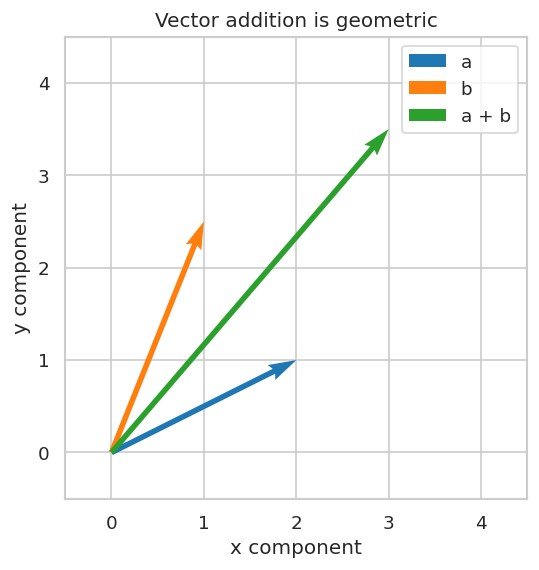

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
viz_vec_a = np.array([2.0, 1.0])
viz_vec_b = np.array([1.0, 2.5])
viz_vec_sum = viz_vec_a + viz_vec_b
fig, ax = plt.subplots(figsize=(6, 5))
for vec, label, color in [(viz_vec_a, "a", "tab:blue"),
                          (viz_vec_b, "b", "tab:orange"),
                          (viz_vec_sum, "a + b", "tab:green")]:
    ax.quiver(0, 0, vec[0], vec[1], angles="xy", scale_units="xy", scale=1,
              color=color, width=0.012, label=label)
ax.set_xlim(-0.5, 4.5); ax.set_ylim(-0.5, 4.5)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x component"); ax.set_ylabel("y component")
ax.set_title("Vector addition is geometric")
ax.legend(); plt.show()

### Compare vector length and direction

The next table uses a `pandas.DataFrame` to keep named measurements together. A cosine similarity close to 1 means that two nonzero vectors point in similar directions; a value close to 0 means that they are approximately perpendicular. Magnitudes can differ while cosine similarity remains unchanged.

01_vectors_and_norms.ipynb:cell17:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,vector,x,y,L1 norm,L2 norm,cosine with a
0,a,2.0,1.0,3.0,2.236,1.000
1,b,1.0,2.5,3.5,2.693,0.747
2,a + b,3.0,3.5,6.5,4.610,0.922


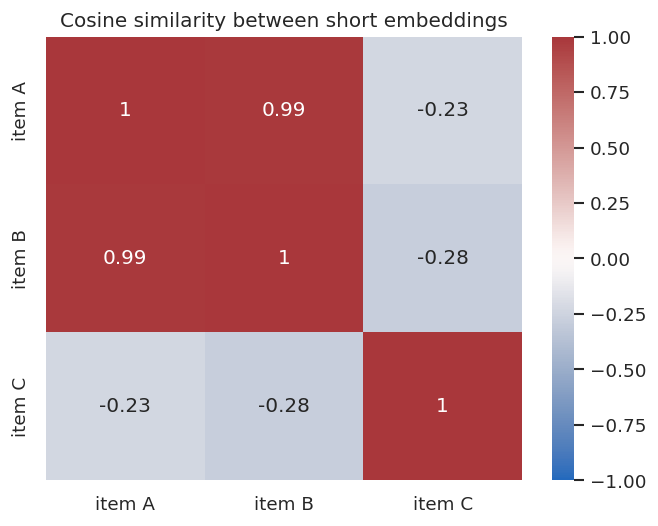

In [8]:
viz_vec_rows = []
for viz_vec_name, viz_vec_value in [("a", viz_vec_a), ("b", viz_vec_b), ("a + b", viz_vec_sum)]:
    viz_vec_rows.append({"vector": viz_vec_name, "x": viz_vec_value[0], "y": viz_vec_value[1],
                         "L1 norm": np.linalg.norm(viz_vec_value, ord=1),
                         "L2 norm": np.linalg.norm(viz_vec_value),
                         "cosine with a": np.dot(viz_vec_value, viz_vec_a) / (np.linalg.norm(viz_vec_value) * np.linalg.norm(viz_vec_a))})
display(pd.DataFrame(viz_vec_rows).round(3))

viz_embed = np.array([[1.0, 0.2, 0.1], [0.9, 0.1, 0.2], [-0.4, 0.8, 0.2]])
viz_embed_norm = viz_embed / np.linalg.norm(viz_embed, axis=1, keepdims=True)
viz_cosine_matrix = viz_embed_norm @ viz_embed_norm.T
sns.heatmap(viz_cosine_matrix, annot=True, vmin=-1, vmax=1, cmap="vlag",
            xticklabels=["item A", "item B", "item C"],
            yticklabels=["item A", "item B", "item C"])
plt.title("Cosine similarity between short embeddings"); plt.show()

**Practical cautions:** `np.linalg.norm(v) == 0` means that cosine similarity is undefined. Also check shapes before taking a dot product: NumPy may broadcast some arrays, which can produce a valid-looking but unintended result.

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Compute the L2 distance between [1, 2] and [4, 6].

In [9]:
a = np.array([1, 2], dtype=float)
b = np.array([4, 6], dtype=float)
print(np.linalg.norm(a - b))

5.0


### Exercise 2
Exercise 2: Normalize a nonzero vector to unit L2 length.

In [10]:
v = np.array([3.0, 4.0])
unit_v = v / np.linalg.norm(v)
print(unit_v, np.linalg.norm(unit_v))

[0.6 0.8] 1.0


## Key takeaways
- Vectors represent features, embeddings, parameters, and gradients.
- Norms quantify size; cosine similarity quantifies direction.
- Always verify shapes and explicitly handle zero vectors.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.